In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import os

for d in os.listdir("/kaggle/input/datasets/shawcholghosh/database-for-emotion"):
    print(d)

Database for Emotion Recognition System Based on EEG Signals and Various Computer Games - GAMEEMO


In [3]:
import os

BASE = "/kaggle/input/datasets/shawcholghosh/database-for-emotion"   # upore je folder name dekhle, oita diye path ta ber korbe

# prothom 3 level porjonto folder structure
for root, dirs, files in os.walk(BASE):
    depth = root.replace(BASE, "").count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(root) + "/")
        if depth == 3:
            for f in sorted(files)[:10]:
                print("  " * (depth + 1) + f)

database-for-emotion/
  Database for Emotion Recognition System Based on EEG Signals and Various Computer Games - GAMEEMO/
    GAMEEMO/
      (S01)/
      (S02)/
      (S03)/
      (S04)/
      (S05)/
      (S06)/
      (S07)/
      (S08)/
      (S09)/
      (S10)/
      (S11)/
      (S12)/
      (S13)/
      (S14)/
      (S15)/
      (S16)/
      (S17)/
      (S18)/
      (S19)/
      (S20)/
      (S21)/
      (S22)/
      (S23)/
      (S24)/
      (S25)/
      (S26)/
      (S27)/
      (S28)/
      Gameplays/


In [7]:
import os, re

# 1) /kaggle/input er bhitore ki ache
for d in os.listdir("/kaggle/input"):
    print("TOP:", d)

# 2) kothay "Raw EEG Data" folder ache, ar tar bhitore ki file
found = 0
for root, dirs, files in os.walk("/kaggle/input"):
    if "raw" in root.lower() and files:
        print("\nFOLDER:", root)
        print("FILES :", files[:6])
        found += 1
        if found == 2:
            break

if found == 0:
    print("\nKono 'raw' folder paoa jay ni. Dataset add kora hoy ni naki onno kothao ache?")
    total = sum(len(f) for _, _, f in os.walk("/kaggle/input"))
    print("Total file in /kaggle/input:", total)

TOP: datasets

FOLDER: /kaggle/input/datasets/shawcholghosh/database-for-emotion/Database for Emotion Recognition System Based on EEG Signals and Various Computer Games - GAMEEMO/GAMEEMO/(S01)/Raw EEG Data/.csv format
FILES : ['S01G1AllRawChannels.csv', 'S01G2AllRawChannels.csv', 'S01G3AllRawChannels.csv', 'S01G4AllRawChannels.csv']

FOLDER: /kaggle/input/datasets/shawcholghosh/database-for-emotion/Database for Emotion Recognition System Based on EEG Signals and Various Computer Games - GAMEEMO/GAMEEMO/(S01)/Raw EEG Data/.mat format
FILES : ['S01G1AllRawChannels.mat', 'S01G2AllRawChannels.mat', 'S01G3AllRawChannels.mat', 'S01G4AllRawChannels.mat']


# CELL-1

In [8]:
!pip install -q mne
import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt, mne
from tqdm.auto import tqdm
mne.set_log_level("ERROR")

BASE = "/kaggle/input"
SFREQ = 128
CH = ["AF3","F7","F3","FC5","T7","P7","O1","O2","P8","T8","FC6","F4","F8","AF4"]
CLASSES = ["boring","calm","horror","funny"]   # G1 Train Sim, G2 Unravel, G3 Slender, G4 Goat/Coast Sim

raw_files, pre_files = {}, {}
for root, _, files in os.walk(BASE):
    for f in files:
        m = re.match(r"S(\d+)G(\d)", f)          # G, C na
        if m and f.lower().endswith(".csv"):
            key = (int(m.group(1)), int(m.group(2)))
            if "Raw EEG Data" in root:       raw_files[key] = os.path.join(root, f)
            elif "Preprocessed" in root:     pre_files[key] = os.path.join(root, f)
print("raw:", len(raw_files), "| preprocessed:", len(pre_files), "(expected 112 each)")

raw: 112 | preprocessed: 112 (expected 112 each)


# CELL-2

In [15]:
def load_mne(path):
    df = pd.read_csv(path)
    df.columns = df.columns.astype(str).str.strip()
    df = df.select_dtypes("number")
    df = df[CH]                                   # name diye select, tai CSV er alphabetical order problem na
    data = df.values.T
    data = (data - data.mean(axis=1, keepdims=True)) * 1e-6
    info = mne.create_info(CH, SFREQ, ch_types="eeg")
    raw = mne.io.RawArray(data, info)
    raw.set_montage("standard_1005", on_missing="ignore")
    return raw

# CELL-3

ICA excluded components: []


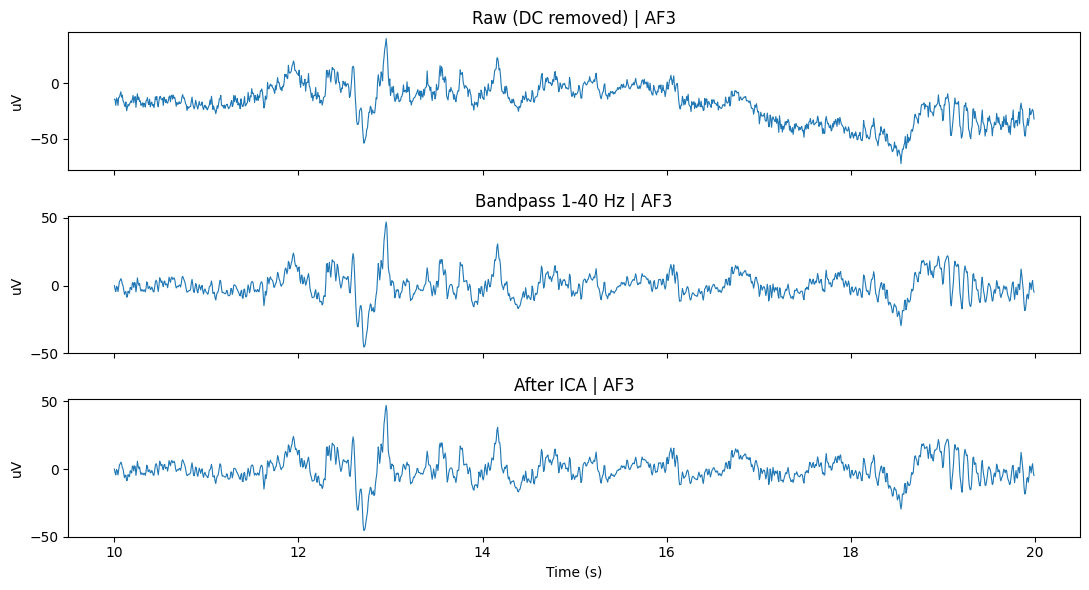

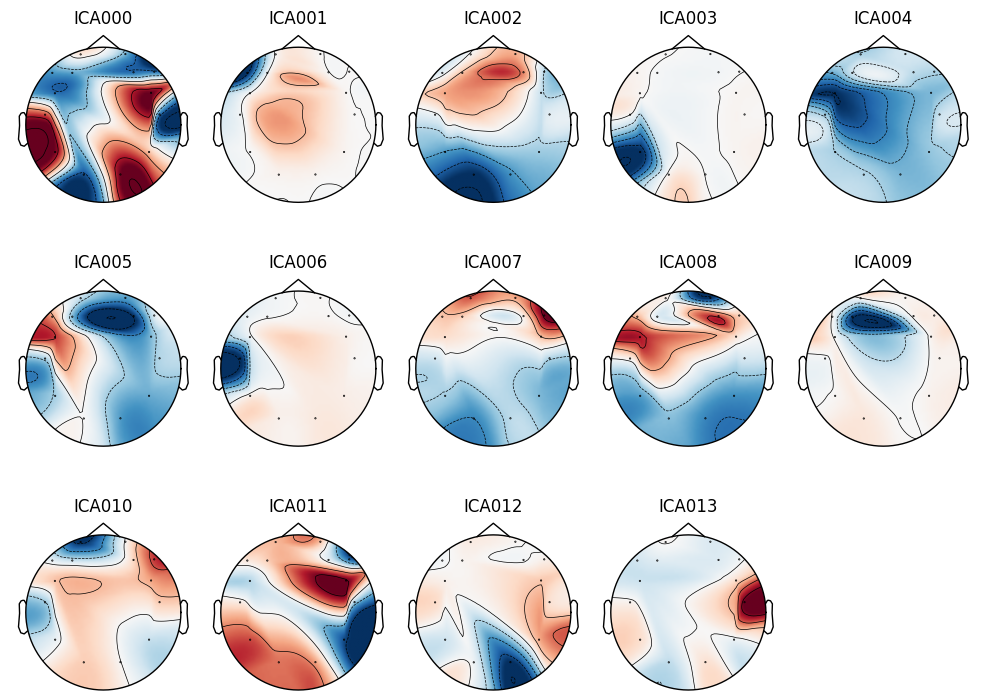

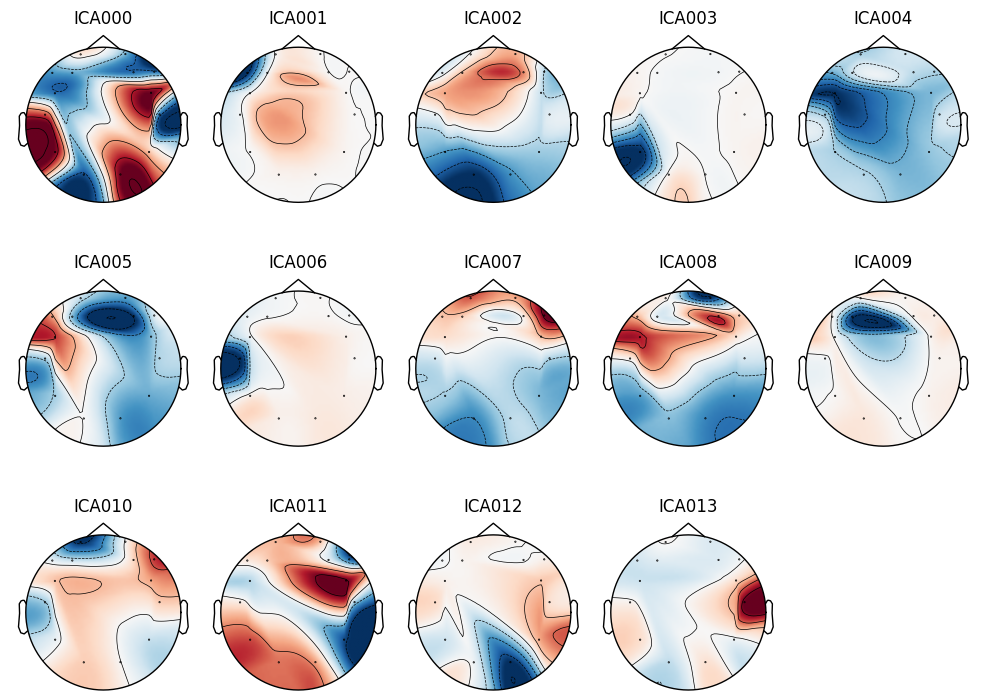

In [16]:
def clean(raw):
    f = raw.copy().filter(1.0, 40.0)
    ica = mne.preprocessing.ICA(n_components=14, random_state=42, max_iter=500)
    ica.fit(f)
    try:
        idx, _ = ica.find_bads_eog(f, ch_name=["AF3", "AF4"])   # EOG channel nai, frontal proxy
        ica.exclude = list(idx)[:2]
    except Exception:
        ica.exclude = []
    return ica.apply(f.copy()), ica

raw0 = load_mne(raw_files[(1, 1)])
filt0 = raw0.copy().filter(1.0, 40.0)
clean0, ica0 = clean(raw0)
print("ICA excluded components:", ica0.exclude)

t0, t1 = 10 * SFREQ, 20 * SFREQ
fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for a, r_, title in zip(ax, [raw0, filt0, clean0], ["Raw (DC removed)", "Bandpass 1-40 Hz", "After ICA"]):
    a.plot(np.arange(t0, t1) / SFREQ, r_.get_data(picks="AF3")[0, t0:t1] * 1e6, lw=0.8)
    a.set_title(title + " | AF3"); a.set_ylabel("uV")
ax[-1].set_xlabel("Time (s)"); plt.tight_layout()
plt.savefig("preprocessing_comparison.png", dpi=150); plt.show()
ica0.plot_components()

# CELL-4

In [11]:
from mne.time_frequency import psd_array_welch
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}

def de_features(X):                      # X: (n_epochs, 14, 512)
    psd, freqs = psd_array_welch(X, SFREQ, fmin=1, fmax=40, n_fft=256)
    out = []
    for lo, hi in BANDS.values():
        p = psd[..., (freqs >= lo) & (freqs < hi)].mean(-1)
        out.append(np.log(p + 1e-12))    # differential entropy approx (Gaussian assumption)
    return np.concatenate(out, axis=1)   # (n_epochs, 70)

def build(kind):
    files = raw_files if kind == "ours" else pre_files
    Xs, Fs, ys, gs = [], [], [], []
    for (s, c), p in tqdm(sorted(files.items())):
        raw = load_mne(p)
        if kind == "ours":
            raw, _ = clean(raw)
        ep = mne.make_fixed_length_epochs(raw, duration=4.0, preload=True)
        X = ep.get_data().astype(np.float32)
        Xs.append(X); Fs.append(de_features(X))
        ys.append(np.full(len(X), c - 1)); gs.append(np.full(len(X), s))
    return np.concatenate(Xs), np.concatenate(Fs), np.concatenate(ys), np.concatenate(gs)

data = {}
for kind in ["ours", "authors"]:
    data[kind] = build(kind)
    print(kind, [a.shape for a in data[kind]])
np.savez_compressed("/kaggle/working/ours.npz", *data["ours"])
np.savez_compressed("/kaggle/working/authors.npz", *data["authors"])

  0%|          | 0/112 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_fastica.py:127: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


ours [(8288, 14, 512), (8288, 70), (8288,), (8288,)]


  0%|          | 0/112 [00:00<?, ?it/s]

authors [(8288, 14, 512), (8288, 70), (8288,), (8288,)]


# CELL-5

In [12]:
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

def subj_norm(F, g):
    F = F.copy()
    for s in np.unique(g):
        m = g == s
        F[m] = (F[m] - F[m].mean(0)) / (F[m].std(0) + 1e-8)
    return F

models = {"SVM": make_pipeline(StandardScaler(), SVC(C=10, gamma="scale")),
          "RF": RandomForestClassifier(300, n_jobs=-1, random_state=42)}
rows, preds = [], {}
for kind in ["ours", "authors"]:
    _, F, y, g = data[kind]
    F = subj_norm(F, g)
    for name, mdl in models.items():
        p = cross_val_predict(mdl, F, y, groups=g, cv=GroupKFold(5))
        preds[(kind, name)] = p
        rows.append([kind, name, "subject-wise", accuracy_score(y, p), f1_score(y, p, average="macro")])
    # leakage demo: random split
    p = cross_val_predict(models["RF"], F, y, cv=KFold(5, shuffle=True, random_state=42))
    rows.append([kind, "RF", "random (leaky)", accuracy_score(y, p), f1_score(y, p, average="macro")])

res = pd.DataFrame(rows, columns=["preprocessing", "model", "split", "accuracy", "macro_F1"]).round(3)
print(res.to_string(index=False))

preprocessing model          split  accuracy  macro_F1
         ours   SVM   subject-wise     0.893     0.893
         ours    RF   subject-wise     0.768     0.768
         ours    RF random (leaky)     0.875     0.875
      authors   SVM   subject-wise     0.952     0.952
      authors    RF   subject-wise     0.856     0.856
      authors    RF random (leaky)     0.863     0.863


# CELL-6

In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models as km
from sklearn.model_selection import GroupShuffleSplit

def cnn():
    return km.Sequential([
        layers.Input((512, 14)),
        layers.Conv1D(32, 7, activation="relu"), layers.BatchNormalization(), layers.MaxPool1D(4),
        layers.Conv1D(64, 5, activation="relu"), layers.BatchNormalization(), layers.MaxPool1D(4),
        layers.Conv1D(128, 3, activation="relu"), layers.GlobalAveragePooling1D(),
        layers.Dropout(0.5), layers.Dense(4, activation="softmax")])

dl_rows = []
for kind in ["ours", "authors"]:
    X, _, y, g = data[kind]
    X = X.transpose(0, 2, 1)
    X = (X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-8)   # per-epoch z-score
    tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=42).split(X, y, g))
    m = cnn()
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(X[tr], y[tr], validation_split=0.1, epochs=30, batch_size=64, verbose=0,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)])
    p = m.predict(X[te], verbose=0).argmax(1)
    dl_rows.append([kind, "1D-CNN", "held-out subjects", accuracy_score(y[te], p), f1_score(y[te], p, average="macro")])
print(pd.DataFrame(dl_rows, columns=res.columns).round(3).to_string(index=False))

I0000 00:00:1792733796.300247      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792733796.304311      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1792733806.131335     510 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


preprocessing  model             split  accuracy  macro_F1
         ours 1D-CNN held-out subjects     0.444     0.438
      authors 1D-CNN held-out subjects     0.319     0.243


# CELL-6V2

In [18]:
def subj_norm_raw(X, g):          # X: (n, 512, 14)
    X = X.copy()
    for s in np.unique(g):
        m = g == s
        mu = X[m].mean(axis=(0, 1), keepdims=True)
        sd = X[m].std(axis=(0, 1), keepdims=True) + 1e-8
        X[m] = (X[m] - mu) / sd
    return X

dl_rows = []
for kind in ["ours", "authors"]:
    X, _, y, g = data[kind]
    X = subj_norm_raw(X.transpose(0, 2, 1), g)
    accs, f1s = [], []
    for tr, te in GroupKFold(5).split(X, y, g):
        val_subj = np.random.RandomState(42).choice(np.unique(g[tr]), 3, replace=False)
        va = np.isin(g[tr], val_subj)
        tf.keras.backend.clear_session()
        m = cnn()
        m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
        m.fit(X[tr][~va], y[tr][~va], validation_data=(X[tr][va], y[tr][va]),
              epochs=30, batch_size=64, verbose=0,
              callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)])
        p = m.predict(X[te], verbose=0).argmax(1)
        accs.append(accuracy_score(y[te], p)); f1s.append(f1_score(y[te], p, average="macro"))
    dl_rows.append([kind, "1D-CNN", "subject-wise 5-fold",
                    f"{np.mean(accs):.3f} ± {np.std(accs):.3f}", f"{np.mean(f1s):.3f}"])
print(pd.DataFrame(dl_rows, columns=["preprocessing", "model", "split", "accuracy (mean ± sd)", "macro_F1"]).to_string(index=False))

preprocessing  model               split accuracy (mean ± sd) macro_F1
         ours 1D-CNN subject-wise 5-fold        0.633 ± 0.191    0.623
      authors 1D-CNN subject-wise 5-fold        0.623 ± 0.223    0.612


# CELL-7

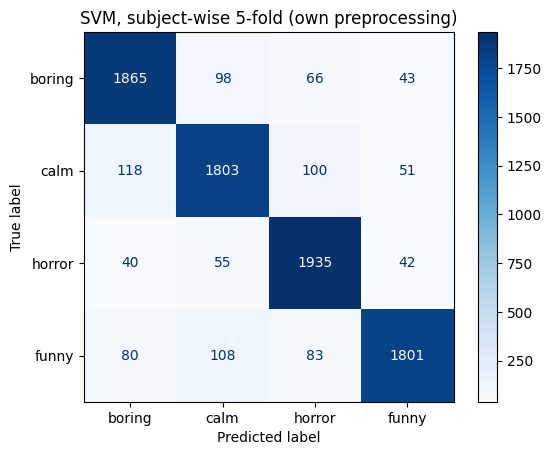

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
_, _, y, _ = data["ours"]
ConfusionMatrixDisplay.from_predictions(y, preds[("ours", "SVM")], display_labels=CLASSES, cmap="Blues")
plt.title("SVM, subject-wise 5-fold (own preprocessing)")
plt.savefig("confusion_matrix.png", dpi=150); plt.show()

# CELL-8

In [17]:
def build_filter_only():
    Xs, Fs, ys, gs = [], [], [], []
    for (s, c), p in tqdm(sorted(raw_files.items())):
        raw = load_mne(p).filter(1.0, 40.0)
        ep = mne.make_fixed_length_epochs(raw, duration=4.0, preload=True)
        X = ep.get_data().astype(np.float32)
        Xs.append(X); Fs.append(de_features(X))
        ys.append(np.full(len(X), c - 1)); gs.append(np.full(len(X), s))
    return np.concatenate(Xs), np.concatenate(Fs), np.concatenate(ys), np.concatenate(gs)

data["filter_only"] = build_filter_only()

rows = []
for kind in ["authors", "ours", "filter_only"]:
    _, F, y, g = data[kind]
    for norm in [True, False]:
        Fn = subj_norm(F, g) if norm else F
        p = cross_val_predict(models["SVM"], Fn, y, groups=g, cv=GroupKFold(5))
        rows.append([kind, "with subj-norm" if norm else "no subj-norm",
                     accuracy_score(y, p), f1_score(y, p, average="macro")])
print(pd.DataFrame(rows, columns=["preprocessing", "normalization", "accuracy", "macro_F1"]).round(3).to_string(index=False))

  0%|          | 0/112 [00:00<?, ?it/s]

preprocessing  normalization  accuracy  macro_F1
      authors with subj-norm     0.952     0.952
      authors   no subj-norm     0.489     0.488
         ours with subj-norm     0.893     0.893
         ours   no subj-norm     0.483     0.482
  filter_only with subj-norm     0.960     0.960
  filter_only   no subj-norm     0.497     0.496


# CELL-9

authors.npz
ours.npz
preprocessing_comparison.png
confusion_matrix.png
.virtual_documents/__notebook_source__.ipynb
figures/ica_components_0.png
results/ml_results.csv
results/cnn_results.csv


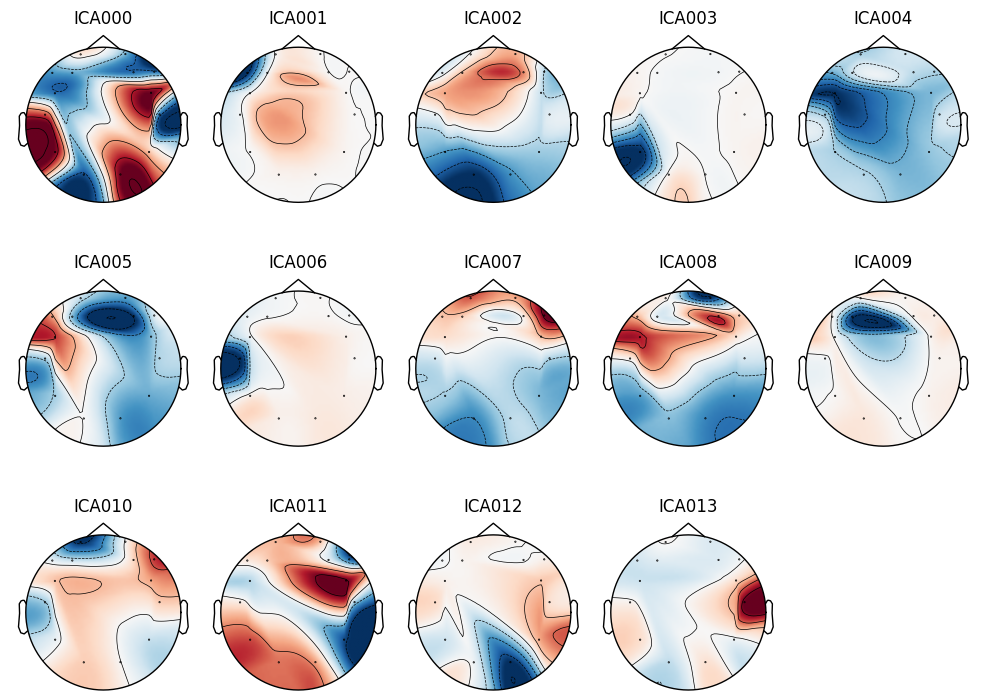

In [19]:
import os
os.makedirs("/kaggle/working/figures", exist_ok=True)
os.makedirs("/kaggle/working/results", exist_ok=True)

# ICA components plot
figs = ica0.plot_components(show=False)
figs = figs if isinstance(figs, list) else [figs]
for i, f in enumerate(figs):
    f.savefig(f"/kaggle/working/figures/ica_components_{i}.png", dpi=150, bbox_inches="tight")

# Cell 5 ar Cell 6 v2 er results
res.to_csv("/kaggle/working/results/ml_results.csv", index=False)
pd.DataFrame(dl_rows, columns=["preprocessing", "model", "split", "accuracy_mean_sd", "macro_F1"]) \
  .to_csv("/kaggle/working/results/cnn_results.csv", index=False)

# kon file ache
for root, _, files in os.walk("/kaggle/working"):
    for f in files:
        print(os.path.join(root, f).replace("/kaggle/working/", ""))

In [20]:
import shutil, glob, os
EX = "/kaggle/working/export"
shutil.rmtree(EX, ignore_errors=True)
os.makedirs(f"{EX}/figures"); os.makedirs(f"{EX}/results")
for f in glob.glob("/kaggle/working/figures/*.png"): shutil.copy(f, f"{EX}/figures")
shutil.copy("/kaggle/working/confusion_matrix.png", f"{EX}/figures")
for f in glob.glob("/kaggle/working/results/*.csv"): shutil.copy(f, f"{EX}/results")
shutil.make_archive("/kaggle/working/export_for_github", "zip", EX)
print(os.listdir(f"{EX}/figures"), os.listdir(f"{EX}/results"))

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
['ica_components_0.png', 'confusion_matrix.png'] ['ml_results.csv', 'cnn_results.csv']
